# Step 3: Inventory Risk Detection

**TradeFlow AI — Tradeling Hackathon**

Uses the improved XGBoost 30-day demand forecasts (Step 2.6) to detect inventory
risks: stockouts, safety-stock violations, excess inventory, and stock ageing.

### Overview

1. Load demand forecasts, inventory, inbound orders, stock ageing, products
2. Calculate inventory requirements (projected ending stock, unmet demand, shortfalls)
3. Simulate daily inventory movements (shipment timing matters)
4. Classify inventory risks (Critical, Warning, Excess, Healthy)
5. Analyze stock ageing (61-90 days, 90+ days, holding costs)
6. Calculate financial impact (lost margin, holding costs, exposure by warehouse)
7. Save results, generate visualizations, run validation checks

---
## 1. Load Data

### 1.1 Imports and dataset loading

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_DIR = Path(r"C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets")

# --- Demand forecasts (from Step 2.6 improved XGBoost) ---
forecast_30d = pd.read_csv(DATA_DIR / "improved_forecast_30d.csv")
daily_forecast = pd.read_csv(DATA_DIR / "improved_daily_forecasts.csv")
daily_forecast["Date"] = pd.to_datetime(daily_forecast["Date"])

# --- Inventory ---
inventory = pd.read_csv(DATA_DIR / "inventory.csv")

# --- Stock ageing ---
stock_ageing = pd.read_csv(DATA_DIR / "stock_ageing.csv")

# --- Inbound orders ---
inbound = pd.read_csv(DATA_DIR / "inbound_orders.csv")
inbound["Expected_Arrival"] = pd.to_datetime(inbound["Expected_Arrival"])

# --- Products ---
products = pd.read_csv(DATA_DIR / "products.csv")

# --- Warehouses ---
warehouses = pd.read_csv(DATA_DIR / "warehouses.csv")

print("Data loaded:")
print(f"  forecast_30d      : {forecast_30d.shape}")
print(f"  daily_forecast    : {daily_forecast.shape}")
print(f"  inventory         : {inventory.shape}")
print(f"  stock_ageing      : {stock_ageing.shape}")
print(f"  inbound_orders    : {inbound.shape}")
print(f"  products          : {products.shape}")
print(f"  warehouses        : {warehouses.shape}")
print(f"\nForecast model: {forecast_30d['Selected_Model'].iloc[0]}")
print(f"Forecast date range: {daily_forecast['Date'].min().date()} → {daily_forecast['Date'].max().date()}")
print(f"\nInbound arrival range: {inbound['Expected_Arrival'].min().date()} → {inbound['Expected_Arrival'].max().date()}")

Data loaded:
  forecast_30d      : (60, 6)
  daily_forecast    : (1800, 4)
  inventory         : (60, 5)
  stock_ageing      : (240, 4)
  inbound_orders    : (42, 6)
  products          : (20, 7)
  warehouses        : (3, 3)

Forecast model: Tuned XGBoost
Forecast date range: 2026-09-29 → 2026-10-28

Inbound arrival range: 2026-10-01 → 2026-10-18


### 1.2 Inspect inventory and inbound columns

In [2]:
print("Inventory columns:", list(inventory.columns))
print("Available_Stock sample stats:")
print(inventory[["Available_Stock", "Reserved_Stock", "Safety_Stock"]].describe().round(1))
print(f"\nInbound columns: {list(inbound.columns)}")
print(f"Total inbound orders: {len(inbound)}")
print(f"Total inbound quantity: {inbound['Quantity'].sum()}")
print(f"\nAge buckets: {stock_ageing['Age_Bucket'].unique().tolist()}")

Inventory columns: ['SKU', 'Warehouse', 'Available_Stock', 'Reserved_Stock', 'Safety_Stock']
Available_Stock sample stats:
       Available_Stock  Reserved_Stock  Safety_Stock
count             60.0            60.0          60.0
mean             681.2             4.5          25.8
std              349.5             3.3           7.1
min              195.0             0.0          15.0
25%              374.8             2.0          19.0
50%              619.5             4.0          25.5
75%              898.2             7.2          32.2
max             1549.0            10.0          39.0

Inbound columns: ['Order_ID', 'SKU', 'Warehouse', 'Quantity', 'Supplier_Lead_Time_Days', 'Expected_Arrival']
Total inbound orders: 42
Total inbound quantity: 2448

Age buckets: ['0-30 days', '31-60 days', '61-90 days', '90+ days']


---

## 2. Calculate Inventory Requirements

### Column Definitions

- `Available_Stock` — physical units on hand **already net of reserved stock**
  (Reserved_Stock is informational; subtracting it again would double-count)
- `Reserved_Stock` — units allocated to existing orders (already excluded from Available)
- `Safety_Stock` — minimum buffer to maintain
- `Expected_Arrival` (inbound) — scheduled arrival date for incoming shipments

### Formulas

- `Projected_Ending_Stock = Available_Stock + Incoming_Stock − Forecast_30d`
- `Expected_Unmet_Demand = max(0, Forecast_30d − (Available_Stock + Incoming_Stock))`
- `Safety_Stock_Shortfall = max(0, Safety_Stock − Projected_Ending_Stock)`
- `Excess_Stock = max(0, Projected_Ending_Stock − Safety_Stock)`

### 2.1 Merge forecasts with inventory and products

In [3]:
# Merge forecast_30d with inventory
inv_risk = (
    forecast_30d
    .merge(inventory, on=["SKU", "Warehouse"], how="left")
    .merge(products[["SKU", "Category", "Unit_Cost_AED", "Selling_Price_AED",
                     "Profit_Margin_AED", "Holding_Cost_Per_Unit_Day_AED"]],
            on="SKU", how="left")
)

print(f"Merged shape: {inv_risk.shape}")
print(f"Any null Available_Stock: {inv_risk['Available_Stock'].isna().sum()}")
inv_risk.head(5)

Merged shape: (60, 14)
Any null Available_Stock: 0


,SKU,Warehouse,Forecast_30d,Lower_Bound,Upper_Bound,Selected_Model,Available_Stock,Reserved_Stock,Safety_Stock,Category,Unit_Cost_AED,Selling_Price_AED,Profit_Margin_AED,Holding_Cost_Per_Unit_Day_AED
0,SKU-001,Abu Dhabi,107.92,101.12,114.72,Tuned XGBoost,1035,6,23,Chargers,119.48,170.32,50.84,0.0597
1,SKU-001,Dubai,121.52,114.72,128.32,Tuned XGBoost,1533,9,31,Chargers,119.48,170.32,50.84,0.0597
2,SKU-001,Sharjah,80.66,73.86,87.46,Tuned XGBoost,413,3,27,Chargers,119.48,170.32,50.84,0.0597
3,SKU-002,Abu Dhabi,74.63,67.83,81.43,Tuned XGBoost,503,10,17,Chargers,130.91,200.15,69.24,0.0655
4,SKU-002,Dubai,94.06,87.26,100.86,Tuned XGBoost,261,8,34,Chargers,130.91,200.15,69.24,0.0655


### 2.2 Calculate incoming shipments within 30 days

In [4]:
# Sum inbound shipments per SKU-warehouse (all are within the forecast period)
inbound_summary = (
    inbound
    .groupby(["SKU", "Warehouse"])
    .agg(Incoming_Stock=("Quantity", "sum"),
         Inbound_Orders=("Order_ID", "count"))
    .reset_index()
)

# Merge into inv_risk
inv_risk = inv_risk.merge(inbound_summary, on=["SKU", "Warehouse"], how="left")
inv_risk["Incoming_Stock"] = inv_risk["Incoming_Stock"].fillna(0)
inv_risk["Inbound_Orders"] = inv_risk["Inbound_Orders"].fillna(0)

print(f"Combos with inbound shipments: {(inv_risk['Incoming_Stock'] > 0).sum()}/60")
print(f"Total incoming stock: {inv_risk['Incoming_Stock'].sum()}")
inv_risk[["SKU", "Warehouse", "Incoming_Stock", "Inbound_Orders"]].head(10)

Combos with inbound shipments: 42/60
Total incoming stock: 2448.0


,SKU,Warehouse,Incoming_Stock,Inbound_Orders
0,SKU-001,Abu Dhabi,95.0,1.0
1,SKU-001,Dubai,94.0,1.0
2,SKU-001,Sharjah,26.0,1.0
3,SKU-002,Abu Dhabi,50.0,1.0
4,SKU-002,Dubai,0.0,0.0
5,SKU-002,Sharjah,0.0,0.0
6,SKU-003,Abu Dhabi,21.0,1.0
7,SKU-003,Dubai,44.0,1.0
8,SKU-003,Sharjah,0.0,0.0
9,SKU-004,Abu Dhabi,0.0,0.0


### 2.3 Calculate projected ending stock and shortfalls

In [5]:
# Projected ending stock
inv_risk["Projected_Ending_Stock"] = (
    inv_risk["Available_Stock"] + inv_risk["Incoming_Stock"] - inv_risk["Forecast_30d"]
)

# Expected unmet demand (stock not available to cover forecast)
inv_risk["Expected_Unmet_Demand"] = np.maximum(
    0, inv_risk["Forecast_30d"] - (inv_risk["Available_Stock"] + inv_risk["Incoming_Stock"])
)

# Safety stock shortfall (ending stock below safety stock)
inv_risk["Safety_Stock_Shortfall"] = np.maximum(
    0, inv_risk["Safety_Stock"] - inv_risk["Projected_Ending_Stock"]
)

# Excess stock (ending stock above safety stock threshold)
inv_risk["Excess_Stock"] = np.maximum(
    0, inv_risk["Projected_Ending_Stock"] - inv_risk["Safety_Stock"]
)

# Show summary
print("Inventory Requirements Summary:")
print(f"  Total forecast demand    : {inv_risk['Forecast_30d'].sum():.1f}")
print(f"  Total available stock     : {inv_risk['Available_Stock'].sum():.1f}")
print(f"  Total incoming stock      : {inv_risk['Incoming_Stock'].sum():.1f}")
print(f"  Total projected ending    : {inv_risk['Projected_Ending_Stock'].sum():.1f}")
print(f"  Total expected unmet      : {inv_risk['Expected_Unmet_Demand'].sum():.1f}")
print(f"  Total safety shortfall     : {inv_risk['Safety_Stock_Shortfall'].sum():.1f}")
print(f"  Total excess stock         : {inv_risk['Excess_Stock'].sum():.1f}")
print(f"\n  Combos with unmet demand  : {(inv_risk['Expected_Unmet_Demand'] > 0).sum()}")
print(f"  Combos with safety shortfall: {(inv_risk['Safety_Stock_Shortfall'] > 0).sum()}")
print(f"  Combos with excess stock   : {(inv_risk['Excess_Stock'] > 0).sum()}")

Inventory Requirements Summary:
  Total forecast demand    : 6385.1
  Total available stock     : 40872.0
  Total incoming stock      : 2448.0
  Total projected ending    : 36934.9
  Total expected unmet      : 0.0
  Total safety shortfall     : 0.0
  Total excess stock         : 35384.9

  Combos with unmet demand  : 0
  Combos with safety shortfall: 0
  Combos with excess stock   : 60


---

## 3. Simulate Daily Inventory

For each SKU-warehouse combination over 30 days:
1. Start with `Available_Stock` (net of reserved)
2. Add inbound shipments on their `Expected_Arrival` date
3. Subtract daily forecast demand
4. Track fulfilled and unmet demand (physical stock ≥ 0)
5. Record first projected stockout date
6. Track safety-stock violations

Daily unmet demand from simulation may differ from aggregate calculation because
shipment timing matters — a shipment arriving on day 10 can cover demand from day 10+.

### 3.1 Build daily inbound shipment schedule

In [6]:
# Create a daily inbound schedule: one row per SKU-Warehouse-Date with incoming quantity
inbound_daily = inbound[["SKU", "Warehouse", "Expected_Arrival", "Quantity"]].copy()
inbound_daily = inbound_daily.rename(columns={"Expected_Arrival": "Date", "Quantity": "Incoming_Qty"})
inbound_daily = inbound_daily.groupby(["SKU", "Warehouse", "Date"])["Incoming_Qty"].sum().reset_index()

print(f"Daily inbound schedule: {len(inbound_daily)} rows")
print(f"Date range: {inbound_daily['Date'].min().date()} → {inbound_daily['Date'].max().date()}")
inbound_daily.head(10)

Daily inbound schedule: 42 rows
Date range: 2026-10-01 → 2026-10-18


,SKU,Warehouse,Date,Incoming_Qty
0,SKU-001,Abu Dhabi,2026-10-13,95
1,SKU-001,Dubai,2026-10-18,94
2,SKU-001,Sharjah,2026-10-08,26
3,SKU-002,Abu Dhabi,2026-10-18,50
4,SKU-003,Abu Dhabi,2026-10-15,21
5,SKU-003,Dubai,2026-10-02,44
6,SKU-005,Abu Dhabi,2026-10-11,55
7,SKU-005,Dubai,2026-10-13,36
8,SKU-005,Sharjah,2026-10-13,59
9,SKU-006,Abu Dhabi,2026-10-07,81


### 3.2 Run daily inventory simulation

In [7]:
# Get the list of future dates
future_dates = sorted(daily_forecast["Date"].unique())
n_days = len(future_dates)

# Prepare inventory starting point
inv_start = inventory.set_index(["SKU", "Warehouse"])["Available_Stock"].to_dict()
safety_stock_map = inventory.set_index(["SKU", "Warehouse"])["Safety_Stock"].to_dict()

# Inbound schedule as dict: (sku, wh, date) -> qty
inbound_map = {}
for _, row in inbound_daily.iterrows():
    key = (row["SKU"], row["Warehouse"], row["Date"])
    inbound_map[key] = inbound_map.get(key, 0) + row["Incoming_Qty"]

# Get unique SKU-warehouse combos
combos = inventory[["SKU", "Warehouse"]].drop_duplicates().values.tolist()

daily_proj_rows = []
sim_results = {}  # (sku, wh) -> summary dict

for sku, wh in combos:
    stock = float(inv_start[(sku, wh)])
    safety = float(safety_stock_map[(sku, wh)])
    cumulative_demand = 0.0
    cumulative_inbound = 0.0
    cumulative_fulfilled = 0.0
    cumulative_unmet = 0.0
    first_stockout_date = None
    safety_violation_days = 0
    days_below_safety = 0
    starting_stock = stock

    for day_idx, dt in enumerate(future_dates):
        # Add inbound shipment arriving on this date
        incoming = inbound_map.get((sku, wh, dt), 0)
        stock += incoming
        cumulative_inbound += incoming

        # Get forecast demand for this day
        fc_row = daily_forecast[(daily_forecast["SKU"] == sku) &
                                (daily_forecast["Warehouse"] == wh) &
                                (daily_forecast["Date"] == dt)]
        demand = fc_row["Predicted_Demand"].values[0] if len(fc_row) > 0 else 0.0
        cumulative_demand += demand

        # Fulfill demand from stock
        fulfilled = min(stock, demand)
        unmet = max(0, demand - stock)
        stock = max(0, stock - fulfilled)
        cumulative_fulfilled += fulfilled
        cumulative_unmet += unmet

        # Track stockout (first day stock hits 0)
        if stock == 0 and first_stockout_date is None:
            first_stockout_date = dt

        # Safety stock violation
        if stock < safety:
            days_below_safety += 1
            if unmet > 0:
                safety_violation_days += 1

        daily_proj_rows.append({
            "Date": dt,
            "SKU": sku,
            "Warehouse": wh,
            "Starting_Stock": starting_stock if day_idx == 0 else None,  # only day 0
            "Incoming_Qty": incoming,
            "Daily_Demand": demand,
            "Fulfilled_Demand": fulfilled,
            "Unmet_Demand": unmet,
            "Ending_Stock": stock,
            "Cumulative_Inbound": cumulative_inbound,
            "Cumulative_Demand": cumulative_demand,
            "Cumulative_Fulfilled": cumulative_fulfilled,
            "Cumulative_Unmet": cumulative_unmet,
            "Safety_Stock": safety,
            "Below_Safety_Stock": stock < safety,
        })
        starting_stock = stock  # carry forward

    sim_results[(sku, wh)] = {
        "Starting_Stock": inv_start[(sku, wh)],
        "Total_Incoming": cumulative_inbound,
        "Total_Demand": cumulative_demand,
        "Total_Fulfilled": cumulative_fulfilled,
        "Total_Unmet_Demand": cumulative_unmet,
        "First_Stockout_Date": first_stockout_date,
        "Days_Below_Safety": days_below_safety,
        "Ending_Stock": stock,
    }

daily_proj = pd.DataFrame(daily_proj_rows)
# Fill Starting_Stock forward for each SKU-Warehouse (carry the previous Ending_Stock)
daily_proj = daily_proj.sort_values(["SKU", "Warehouse", "Date"]).reset_index(drop=True)
for (sku, wh), grp in daily_proj.groupby(["SKU", "Warehouse"]):
    prev = None
    for idx in grp.index:
        if pd.isna(daily_proj.at[idx, "Starting_Stock"]):
            daily_proj.at[idx, "Starting_Stock"] = prev
        prev = daily_proj.at[idx, "Ending_Stock"]

print(f"Daily inventory projection: {daily_proj.shape}")
print(f"Unique dates: {daily_proj['Date'].nunique()}")
print(f"Unique SKU×Warehouse: {daily_proj.groupby(['SKU', 'Warehouse']).ngroups}")
daily_proj.head(10)

Daily inventory projection: (1800, 15)
Unique dates: 30
Unique SKU×Warehouse: 60


,Date,SKU,Warehouse,Starting_Stock,Incoming_Qty,Daily_Demand,Fulfilled_Demand,Unmet_Demand,Ending_Stock,Cumulative_Inbound,Cumulative_Demand,Cumulative_Fulfilled,Cumulative_Unmet,Safety_Stock,Below_Safety_Stock
0,2026-09-29,SKU-001,Abu Dhabi,1035.000000,0,3.719754,3.719754,0,1031.280246,0.0,3.719754,3.719754,0.0,23.0,False
1,2026-09-30,SKU-001,Abu Dhabi,1031.280246,0,3.854668,3.854668,0,1027.425578,0.0,7.574422,7.574422,0.0,23.0,False
2,2026-10-01,SKU-001,Abu Dhabi,1027.425578,0,3.830968,3.830968,0,1023.594610,0.0,11.405390,11.405390,0.0,23.0,False
3,2026-10-02,SKU-001,Abu Dhabi,1023.594610,0,3.825195,3.825195,0,1019.769415,0.0,15.230585,15.230585,0.0,23.0,False
4,2026-10-03,SKU-001,Abu Dhabi,1019.769415,0,3.175224,3.175224,0,1016.594192,0.0,18.405808,18.405808,0.0,23.0,False
5,2026-10-04,SKU-001,Abu Dhabi,1016.594192,0,2.876137,2.876137,0,1013.718055,0.0,21.281945,21.281945,0.0,23.0,False
6,2026-10-05,SKU-001,Abu Dhabi,1013.718055,0,3.836169,3.836169,0,1009.881886,0.0,25.118114,25.118114,0.0,23.0,False
7,2026-10-06,SKU-001,Abu Dhabi,1009.881886,0,3.763114,3.763114,0,1006.118771,0.0,28.881229,28.881229,0.0,23.0,False
8,2026-10-07,SKU-001,Abu Dhabi,1006.118771,0,3.706002,3.706002,0,1002.412769,0.0,32.587231,32.587231,0.0,23.0,False
9,2026-10-08,SKU-001,Abu Dhabi,1002.412769,0,3.686948,3.686948,0,998.725822,0.0,36.274178,36.274178,0.0,23.0,False


### 3.3 Merge simulation results into inventory risk table

In [8]:
# Add simulation results to inv_risk
sim_df = pd.DataFrame([
    {"SKU": k[0], "Warehouse": k[1], **v} for k, v in sim_results.items()
])
inv_risk = inv_risk.merge(sim_df, on=["SKU", "Warehouse"], how="left")

# Use simulation-based unmet demand (more accurate due to shipment timing)
inv_risk["Sim_Unmet_Demand"] = inv_risk["Total_Unmet_Demand"]

# Update the Expected_Unmet_Demand to use simulation result
inv_risk["Expected_Unmet_Demand"] = inv_risk["Sim_Unmet_Demand"]

# Recalculate safety shortfall using simulation ending stock
inv_risk["Projected_Ending_Stock_Sim"] = inv_risk["Ending_Stock"]
inv_risk["Safety_Stock_Shortfall"] = np.maximum(
    0, inv_risk["Safety_Stock"] - inv_risk["Projected_Ending_Stock_Sim"]
)
inv_risk["Excess_Stock"] = np.maximum(
    0, inv_risk["Projected_Ending_Stock_Sim"] - inv_risk["Safety_Stock"]
)

print("Updated with simulation results:")
print(f"  Total simulated unmet demand : {inv_risk['Expected_Unmet_Demand'].sum():.1f}")
print(f"  Combos with unmet demand     : {(inv_risk['Expected_Unmet_Demand'] > 0).sum()}")
print(f"  Combos with stockout date     : {inv_risk['First_Stockout_Date'].notna().sum()}")
print(f"  Total days below safety       : {inv_risk['Days_Below_Safety'].sum()}")
inv_risk[["SKU", "Warehouse", "Forecast_30d", "Available_Stock", "Total_Incoming",
          "Ending_Stock", "Expected_Unmet_Demand", "Safety_Stock_Shortfall", "First_Stockout_Date"]].head(10)

Updated with simulation results:
  Total simulated unmet demand : 0.0
  Combos with unmet demand     : 0
  Combos with stockout date     : 0
  Total days below safety       : 0


,SKU,Warehouse,Forecast_30d,Available_Stock,Total_Incoming,Ending_Stock,Expected_Unmet_Demand,Safety_Stock_Shortfall,First_Stockout_Date
0,SKU-001,Abu Dhabi,107.92,1035,95.0,1022.079267,0.0,0.0,None
1,SKU-001,Dubai,121.52,1533,94.0,1505.484254,0.0,0.0,None
2,SKU-001,Sharjah,80.66,413,26.0,358.342380,0.0,0.0,None
3,SKU-002,Abu Dhabi,74.63,503,50.0,478.369572,0.0,0.0,None
4,SKU-002,Dubai,94.06,261,0.0,166.936525,0.0,0.0,None
5,SKU-002,Sharjah,62.05,474,0.0,411.948426,0.0,0.0,None
6,SKU-003,Abu Dhabi,159.73,315,21.0,176.269092,0.0,0.0,None
7,SKU-003,Dubai,159.74,608,44.0,492.258249,0.0,0.0,None
8,SKU-003,Sharjah,138.35,411,0.0,272.646298,0.0,0.0,None
9,SKU-004,Abu Dhabi,78.08,757,0.0,678.924503,0.0,0.0,None


---

## 4. Identify Inventory Risks

### Risk Classification

| Class | Condition |
|-------|-----------|
| **Critical** | Predicted unmet demand > 0 (stockout expected) |
| **Warning** | Inventory falls below safety stock without unmet demand |
| **Excess** | Projected ending stock > 2× safety stock AND > 2× forecast demand |
| **Healthy** | No significant inventory risk |

### Excess Threshold

Excess stock is defined as projected ending inventory exceeding **2× the safety
stock level AND 2× the 30-day forecast demand** — i.e., enough stock to cover
demand for 60+ days at current rates, far above the safety buffer.

### 4.1 Classify inventory risks

In [9]:
# Excess threshold: ending stock > 2x safety stock AND > 2x forecast
EXCESS_SAFETY_MULT = 2.0
EXCESS_DEMAND_MULT = 2.0

def classify_risk(row):
    if row["Expected_Unmet_Demand"] > 0:
        return "Critical"
    if row["Safety_Stock_Shortfall"] > 0:
        return "Warning"
    if (row["Projected_Ending_Stock_Sim"] > EXCESS_SAFETY_MULT * row["Safety_Stock"] and
        row["Projected_Ending_Stock_Sim"] > EXCESS_DEMAND_MULT * row["Forecast_30d"]):
        return "Excess"
    return "Healthy"

inv_risk["Risk_Class"] = inv_risk.apply(classify_risk, axis=1)

# Count by risk class
risk_counts = inv_risk["Risk_Class"].value_counts()
print("Inventory Risk Distribution:")
print(risk_counts.to_string())
print(f"\nTotal: {len(inv_risk)}")

Inventory Risk Distribution:
Risk_Class
Excess     51
Healthy     9

Total: 60


### 4.2 Risk distribution by warehouse

In [10]:
wh_risk = (
    inv_risk
    .groupby(["Warehouse", "Risk_Class"])
    .size()
    .unstack(fill_value=0)
)
print("Risk Distribution by Warehouse:")
print(wh_risk.to_string())

Risk Distribution by Warehouse:
Risk_Class  Excess  Healthy
Warehouse                  
Abu Dhabi       15        5
Dubai           17        3
Sharjah         19        1


---

## 5. Analyze Stock Ageing

Use `stock_ageing.csv` to identify:
- Inventory aged 61–90 days
- Inventory aged 90+ days
- Percentage of aged stock
- Estimated holding costs

### 5.1 Pivot stock ageing and merge

In [11]:
# Pivot stock_ageing to wide format
ageing_wide = stock_ageing.pivot_table(
    index=["SKU", "Warehouse"],
    columns="Age_Bucket",
    values="Quantity",
    fill_value=0,
).reset_index()
ageing_wide.columns.name = None

# Rename columns for clarity
ageing_wide = ageing_wide.rename(columns={
    "0-30 days": "Age_0_30",
    "31-60 days": "Age_31_60",
    "61-90 days": "Age_61_90",
    "90+ days": "Age_90_Plus",
})

# Calculate totals
ageing_wide["Total_Aged_Stock"] = (
    ageing_wide["Age_0_30"] + ageing_wide["Age_31_60"] +
    ageing_wide["Age_61_90"] + ageing_wide["Age_90_Plus"]
)
ageing_wide["Aged_61_90"] = ageing_wide["Age_61_90"]
ageing_wide["Aged_90_Plus"] = ageing_wide["Age_90_Plus"]
ageing_wide["Aged_60_Plus"] = ageing_wide["Age_61_90"] + ageing_wide["Age_90_Plus"]
ageing_wide["Aged_Pct"] = np.where(
    ageing_wide["Total_Aged_Stock"] > 0,
    ageing_wide["Aged_60_Plus"] / ageing_wide["Total_Aged_Stock"] * 100,
    0,
).round(2)

# Merge into inv_risk
inv_risk = inv_risk.merge(ageing_wide[["SKU", "Warehouse", "Age_0_30", "Age_31_60",
    "Age_61_90", "Age_90_Plus", "Total_Aged_Stock", "Aged_60_Plus", "Aged_Pct"]],
    on=["SKU", "Warehouse"], how="left")

print(f"Stock ageing merged. Shape: {inv_risk.shape}")
print(f"Total aged 61-90 days: {inv_risk['Age_61_90'].sum()}")
print(f"Total aged 90+ days: {inv_risk['Age_90_Plus'].sum()}")
print(f"Total aged 60+ days: {inv_risk['Aged_60_Plus'].sum()}")
print(f"Overall aged %: {inv_risk['Aged_60_Plus'].sum() / inv_risk['Total_Aged_Stock'].sum() * 100:.1f}%")

Stock ageing merged. Shape: (60, 38)
Total aged 61-90 days: 6992.0
Total aged 90+ days: 4424.0
Total aged 60+ days: 11416.0
Overall aged %: 27.9%


### 5.2 Ageing stock flags

In [12]:
# Flag combos with significant ageing stock
# High ageing: > 30% of stock is 60+ days old
inv_risk["High_Ageing_Flag"] = inv_risk["Aged_Pct"] > 30

# Critical ageing: any stock aged 90+ days
inv_risk["Critical_Ageing_Flag"] = inv_risk["Age_90_Plus"] > 0

print("Ageing Stock Flags:")
print(f"  High ageing (>30% aged) : {inv_risk['High_Ageing_Flag'].sum()}")
print(f"  Critical (90+ days)     : {inv_risk['Critical_Ageing_Flag'].sum()}")
print(f"\nTop 10 by aged stock (60+ days):")
print(inv_risk.nlargest(10, "Aged_60_Plus")[["SKU", "Warehouse", "Age_61_90", "Age_90_Plus", "Aged_Pct"]].to_string(index=False))

Ageing Stock Flags:
  High ageing (>30% aged) : 27
  Critical (90+ days)     : 58

Top 10 by aged stock (60+ days):
    SKU Warehouse  Age_61_90  Age_90_Plus  Aged_Pct
SKU-020   Sharjah      205.0        509.0     46.09
SKU-001     Dubai      211.0        269.0     31.31
SKU-015   Sharjah      128.0        299.0     51.76
SKU-011   Sharjah      259.0        150.0     27.34
SKU-017     Dubai      337.0         43.0     51.70
SKU-008     Dubai      230.0        122.0     30.99
SKU-013   Sharjah      237.0        107.0     38.14
SKU-006 Abu Dhabi      320.0          8.0     36.57
SKU-005   Sharjah      283.0         43.0     43.64
SKU-001 Abu Dhabi      286.0         24.0     29.95


---

## 6. Calculate Financial Impact

### Estimates (clearly labelled as simulated)

- **Lost contribution margin** = `Expected_Unmet_Demand × Profit_Margin_AED`
- **Holding cost (aged stock)** = `Aged_60_Plus × Holding_Cost_Per_Unit_Day_AED × 30`
- **Holding cost (excess stock)** = `Excess_Stock × Holding_Cost_Per_Unit_Day_AED × 30`

These are **simulated estimates** based on forecast demand and current holding cost rates.

### 6.1 Calculate financial impact

In [13]:
# Lost contribution margin from unmet demand
inv_risk["Lost_Contribution_Margin_AED"] = (
    inv_risk["Expected_Unmet_Demand"] * inv_risk["Profit_Margin_AED"]
).round(2)

# Holding cost for aged stock (60+ days) over 30 days
inv_risk["Aged_Holding_Cost_AED"] = (
    inv_risk["Aged_60_Plus"] * inv_risk["Holding_Cost_Per_Unit_Day_AED"] * 30
).round(2)

# Holding cost for excess stock over 30 days
inv_risk["Excess_Holding_Cost_AED"] = (
    inv_risk["Excess_Stock"] * inv_risk["Holding_Cost_Per_Unit_Day_AED"] * 30
).round(2)

# Total financial exposure
inv_risk["Total_Financial_Exposure_AED"] = (
    inv_risk["Lost_Contribution_Margin_AED"] +
    inv_risk["Aged_Holding_Cost_AED"] +
    inv_risk["Excess_Holding_Cost_AED"]
).round(2)

print("Financial Impact Summary (AED):")
print(f"  Lost contribution margin : {inv_risk['Lost_Contribution_Margin_AED'].sum():,.2f}")
print(f"  Aged stock holding cost  : {inv_risk['Aged_Holding_Cost_AED'].sum():,.2f}")
print(f"  Excess stock holding cost: {inv_risk['Excess_Holding_Cost_AED'].sum():,.2f}")
print(f"  Total financial exposure : {inv_risk['Total_Financial_Exposure_AED'].sum():,.2f}")
print(f"\n⚠️ These are simulated estimates based on forecast demand.")

Financial Impact Summary (AED):
  Lost contribution margin : 0.00
  Aged stock holding cost  : 14,082.13
  Excess stock holding cost: 46,989.45
  Total financial exposure : 61,071.58

⚠️ These are simulated estimates based on forecast demand.


### 6.2 Financial exposure by warehouse

In [14]:
wh_financial = (
    inv_risk
    .groupby("Warehouse")
    .agg(
        Lost_Margin_AED=("Lost_Contribution_Margin_AED", "sum"),
        Aged_Holding_AED=("Aged_Holding_Cost_AED", "sum"),
        Excess_Holding_AED=("Excess_Holding_Cost_AED", "sum"),
        Total_Exposure_AED=("Total_Financial_Exposure_AED", "sum"),
        Unmet_Demand=("Expected_Unmet_Demand", "sum"),
        Excess_Stock=("Excess_Stock", "sum"),
    )
    .round(2)
    .reset_index()
)
print("Financial Exposure by Warehouse (AED):")
print(wh_financial.to_string(index=False))

Financial Exposure by Warehouse (AED):
Warehouse  Lost_Margin_AED  Aged_Holding_AED  Excess_Holding_AED  Total_Exposure_AED  Unmet_Demand  Excess_Stock
Abu Dhabi              0.0           3264.79            10510.14            13774.93           0.0       7954.10
    Dubai              0.0           5513.79            17599.52            23113.31           0.0      12632.50
  Sharjah              0.0           5303.55            18879.79            24183.34           0.0      14798.33


---
## 7. Save Results

### 7.1 Save inventory_risks.csv

In [15]:
# Select and order columns for final inventory_risks.csv
risk_cols = [
    "SKU", "Warehouse", "Category",
    "Forecast_30d", "Lower_Bound", "Upper_Bound", "Selected_Model",
    "Available_Stock", "Reserved_Stock", "Safety_Stock",
    "Incoming_Stock", "Inbound_Orders",
    "Total_Incoming",
    "Total_Demand", "Total_Fulfilled", "Expected_Unmet_Demand",
    "Projected_Ending_Stock", "Projected_Ending_Stock_Sim", "Ending_Stock",
    "Safety_Stock_Shortfall", "Excess_Stock",
    "First_Stockout_Date", "Days_Below_Safety",
    "Age_0_30", "Age_31_60", "Age_61_90", "Age_90_Plus",
    "Total_Aged_Stock", "Aged_60_Plus", "Aged_Pct",
    "High_Ageing_Flag", "Critical_Ageing_Flag",
    "Risk_Class",
    "Lost_Contribution_Margin_AED", "Aged_Holding_Cost_AED",
    "Excess_Holding_Cost_AED", "Total_Financial_Exposure_AED",
]
inventory_risks = inv_risk[risk_cols].copy()

# Format First_Stockout_Date
inventory_risks["First_Stockout_Date"] = pd.to_datetime(inventory_risks["First_Stockout_Date"])
inventory_risks["First_Stockout_Date"] = inventory_risks["First_Stockout_Date"].dt.strftime("%Y-%m-%d")
inventory_risks["First_Stockout_Date"] = inventory_risks["First_Stockout_Date"].fillna("None")

# Round numeric columns
for col in ["Forecast_30d", "Lower_Bound", "Upper_Bound",
            "Total_Demand", "Total_Fulfilled", "Expected_Unmet_Demand",
            "Projected_Ending_Stock", "Projected_Ending_Stock_Sim", "Ending_Stock",
            "Safety_Stock_Shortfall", "Excess_Stock"]:
    if col in inventory_risks.columns:
        inventory_risks[col] = inventory_risks[col].round(2)

inventory_risks.to_csv(DATA_DIR / "inventory_risks.csv", index=False)
print(f"Saved: {DATA_DIR / 'inventory_risks.csv'} ({len(inventory_risks)} rows)")
inventory_risks.head(10)

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\inventory_risks.csv (60 rows)


,SKU,Warehouse,Category,Forecast_30d,Lower_Bound,Upper_Bound,Selected_Model,Available_Stock,Reserved_Stock,Safety_Stock,...,Total_Aged_Stock,Aged_60_Plus,Aged_Pct,High_Ageing_Flag,Critical_Ageing_Flag,Risk_Class,Lost_Contribution_Margin_AED,Aged_Holding_Cost_AED,Excess_Holding_Cost_AED,Total_Financial_Exposure_AED
0,SKU-001,Abu Dhabi,Chargers,107.92,101.12,114.72,Tuned XGBoost,1035,6,23,...,1035.0,310.0,29.95,False,True,Excess,0.0,555.21,1789.35,2344.56
1,SKU-001,Dubai,Chargers,121.52,114.72,128.32,Tuned XGBoost,1533,9,31,...,1533.0,480.0,31.31,True,True,Excess,0.0,859.68,2640.80,3500.48
2,SKU-001,Sharjah,Chargers,80.66,73.86,87.46,Tuned XGBoost,413,3,27,...,413.0,57.0,13.80,False,True,Excess,0.0,102.09,593.43,695.52
3,SKU-002,Abu Dhabi,Chargers,74.63,67.83,81.43,Tuned XGBoost,503,10,17,...,503.0,61.0,12.13,False,True,Excess,0.0,119.86,906.59,1026.45
4,SKU-002,Dubai,Chargers,94.06,87.26,100.86,Tuned XGBoost,261,8,34,...,261.0,175.0,67.05,True,True,Healthy,0.0,343.88,261.22,605.10
5,SKU-002,Sharjah,Chargers,62.05,55.25,68.85,Tuned XGBoost,474,8,31,...,474.0,188.0,39.66,True,True,Excess,0.0,369.42,748.56,1117.98
6,SKU-003,Abu Dhabi,Chargers,159.73,152.93,166.53,Tuned XGBoost,315,10,16,...,315.0,124.0,39.37,True,True,Healthy,0.0,51.71,66.83,118.54
7,SKU-003,Dubai,Chargers,159.74,152.94,166.54,Tuned XGBoost,608,2,35,...,608.0,306.0,50.33,True,True,Excess,0.0,127.60,190.68,318.28
8,SKU-003,Sharjah,Chargers,138.35,131.55,145.15,Tuned XGBoost,411,3,35,...,411.0,202.0,49.15,True,True,Healthy,0.0,84.23,99.10,183.33
9,SKU-004,Abu Dhabi,Chargers,78.08,71.27,84.88,Tuned XGBoost,757,7,30,...,757.0,92.0,12.15,False,True,Excess,0.0,162.56,1146.65,1309.21


### 7.2 Save daily_inventory_projection.csv

In [16]:
# Ensure proper column order
proj_cols = [
    "Date", "SKU", "Warehouse",
    "Starting_Stock", "Incoming_Qty", "Daily_Demand",
    "Fulfilled_Demand", "Unmet_Demand", "Ending_Stock",
    "Cumulative_Inbound", "Cumulative_Demand",
    "Cumulative_Fulfilled", "Cumulative_Unmet",
    "Safety_Stock", "Below_Safety_Stock",
]
daily_proj_save = daily_proj[proj_cols].copy()
daily_proj_save["Date"] = daily_proj_save["Date"].dt.strftime("%Y-%m-%d")

# Round
for col in ["Starting_Stock", "Incoming_Qty", "Daily_Demand", "Fulfilled_Demand",
            "Unmet_Demand", "Ending_Stock", "Cumulative_Inbound", "Cumulative_Demand",
            "Cumulative_Fulfilled", "Cumulative_Unmet"]:
    daily_proj_save[col] = daily_proj_save[col].round(4)

daily_proj_save.to_csv(DATA_DIR / "daily_inventory_projection.csv", index=False)
print(f"Saved: {DATA_DIR / 'daily_inventory_projection.csv'} ({len(daily_proj_save)} rows)")
daily_proj_save.head(10)

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\daily_inventory_projection.csv (1800 rows)


,Date,SKU,Warehouse,Starting_Stock,Incoming_Qty,Daily_Demand,Fulfilled_Demand,Unmet_Demand,Ending_Stock,Cumulative_Inbound,Cumulative_Demand,Cumulative_Fulfilled,Cumulative_Unmet,Safety_Stock,Below_Safety_Stock
0,2026-09-29,SKU-001,Abu Dhabi,1035.0000,0,3.7198,3.7198,0,1031.2802,0.0,3.7198,3.7198,0.0,23.0,False
1,2026-09-30,SKU-001,Abu Dhabi,1031.2802,0,3.8547,3.8547,0,1027.4256,0.0,7.5744,7.5744,0.0,23.0,False
2,2026-10-01,SKU-001,Abu Dhabi,1027.4256,0,3.8310,3.8310,0,1023.5946,0.0,11.4054,11.4054,0.0,23.0,False
3,2026-10-02,SKU-001,Abu Dhabi,1023.5946,0,3.8252,3.8252,0,1019.7694,0.0,15.2306,15.2306,0.0,23.0,False
4,2026-10-03,SKU-001,Abu Dhabi,1019.7694,0,3.1752,3.1752,0,1016.5942,0.0,18.4058,18.4058,0.0,23.0,False
5,2026-10-04,SKU-001,Abu Dhabi,1016.5942,0,2.8761,2.8761,0,1013.7181,0.0,21.2819,21.2819,0.0,23.0,False
6,2026-10-05,SKU-001,Abu Dhabi,1013.7181,0,3.8362,3.8362,0,1009.8819,0.0,25.1181,25.1181,0.0,23.0,False
7,2026-10-06,SKU-001,Abu Dhabi,1009.8819,0,3.7631,3.7631,0,1006.1188,0.0,28.8812,28.8812,0.0,23.0,False
8,2026-10-07,SKU-001,Abu Dhabi,1006.1188,0,3.7060,3.7060,0,1002.4128,0.0,32.5872,32.5872,0.0,23.0,False
9,2026-10-08,SKU-001,Abu Dhabi,1002.4128,0,3.6869,3.6869,0,998.7258,0.0,36.2742,36.2742,0.0,23.0,False


### 7.3 Save inventory_risk_summary.csv

In [17]:
# Build summary table
summary_rows = []

# Overall summary
summary_rows.append({
    "Metric": "Total SKU-Warehouse Combos", "Value": len(inv_risk), "Unit": "count",
})
summary_rows.append({
    "Metric": "Critical (unmet demand)", "Value": (inv_risk["Risk_Class"]=="Critical").sum(), "Unit": "count",
})
summary_rows.append({
    "Metric": "Warning (below safety)", "Value": (inv_risk["Risk_Class"]=="Warning").sum(), "Unit": "count",
})
summary_rows.append({
    "Metric": "Excess", "Value": (inv_risk["Risk_Class"]=="Excess").sum(), "Unit": "count",
})
summary_rows.append({
    "Metric": "Healthy", "Value": (inv_risk["Risk_Class"]=="Healthy").sum(), "Unit": "count",
})
summary_rows.append({
    "Metric": "Total Forecast Demand", "Value": round(inv_risk["Forecast_30d"].sum(), 1), "Unit": "units",
})
summary_rows.append({
    "Metric": "Total Available Stock", "Value": inv_risk["Available_Stock"].sum(), "Unit": "units",
})
summary_rows.append({
    "Metric": "Total Incoming Stock", "Value": inv_risk["Total_Incoming"].sum(), "Unit": "units",
})
summary_rows.append({
    "Metric": "Total Expected Unmet Demand", "Value": round(inv_risk["Expected_Unmet_Demand"].sum(), 1), "Unit": "units",
})
summary_rows.append({
    "Metric": "Total Safety Stock Shortfall", "Value": round(inv_risk["Safety_Stock_Shortfall"].sum(), 1), "Unit": "units",
})
summary_rows.append({
    "Metric": "Total Excess Stock", "Value": round(inv_risk["Excess_Stock"].sum(), 1), "Unit": "units",
})
summary_rows.append({
    "Metric": "Total Aged Stock (60+ days)", "Value": inv_risk["Aged_60_Plus"].sum(), "Unit": "units",
})
summary_rows.append({
    "Metric": "Total Aged Stock (90+ days)", "Value": inv_risk["Age_90_Plus"].sum(), "Unit": "units",
})
summary_rows.append({
    "Metric": "Lost Contribution Margin", "Value": round(inv_risk["Lost_Contribution_Margin_AED"].sum(), 2), "Unit": "AED",
})
summary_rows.append({
    "Metric": "Aged Holding Cost", "Value": round(inv_risk["Aged_Holding_Cost_AED"].sum(), 2), "Unit": "AED",
})
summary_rows.append({
    "Metric": "Excess Holding Cost", "Value": round(inv_risk["Excess_Holding_Cost_AED"].sum(), 2), "Unit": "AED",
})
summary_rows.append({
    "Metric": "Total Financial Exposure", "Value": round(inv_risk["Total_Financial_Exposure_AED"].sum(), 2), "Unit": "AED",
})

# Add per-warehouse summaries
for wh in inv_risk["Warehouse"].unique():
    sub = inv_risk[inv_risk["Warehouse"] == wh]
    summary_rows.append({
        "Metric": f"{wh} - Unmet Demand", "Value": round(sub["Expected_Unmet_Demand"].sum(), 1), "Unit": "units",
    })
    summary_rows.append({
        "Metric": f"{wh} - Excess Stock", "Value": round(sub["Excess_Stock"].sum(), 1), "Unit": "units",
    })
    summary_rows.append({
        "Metric": f"{wh} - Financial Exposure", "Value": round(sub["Total_Financial_Exposure_AED"].sum(), 2), "Unit": "AED",
    })

risk_summary = pd.DataFrame(summary_rows)
risk_summary.to_csv(DATA_DIR / "inventory_risk_summary.csv", index=False)
print(f"Saved: {DATA_DIR / 'inventory_risk_summary.csv'} ({len(risk_summary)} rows)")
print(risk_summary.to_string(index=False))

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\inventory_risk_summary.csv (26 rows)
                        Metric    Value  Unit
    Total SKU-Warehouse Combos    60.00 count
       Critical (unmet demand)     0.00 count
        Warning (below safety)     0.00 count
                        Excess    51.00 count
                       Healthy     9.00 count
         Total Forecast Demand  6385.10 units
         Total Available Stock 40872.00 units
          Total Incoming Stock  2448.00 units
   Total Expected Unmet Demand     0.00 units
  Total Safety Stock Shortfall     0.00 units
            Total Excess Stock 35384.90 units
   Total Aged Stock (60+ days) 11416.00 units
   Total Aged Stock (90+ days)  4424.00 units
      Lost Contribution Margin     0.00   AED
             Aged Holding Cost 14082.13   AED
           Excess Holding Cost 46989.45   AED
      Total Financial Exposure 61071.58   AED
      Abu Dhabi - Unmet Demand     0.00 units
      A

---
## 8. Visualizations

### 8.1 Inventory risk distribution, shortages, excess, lost margin by warehouse

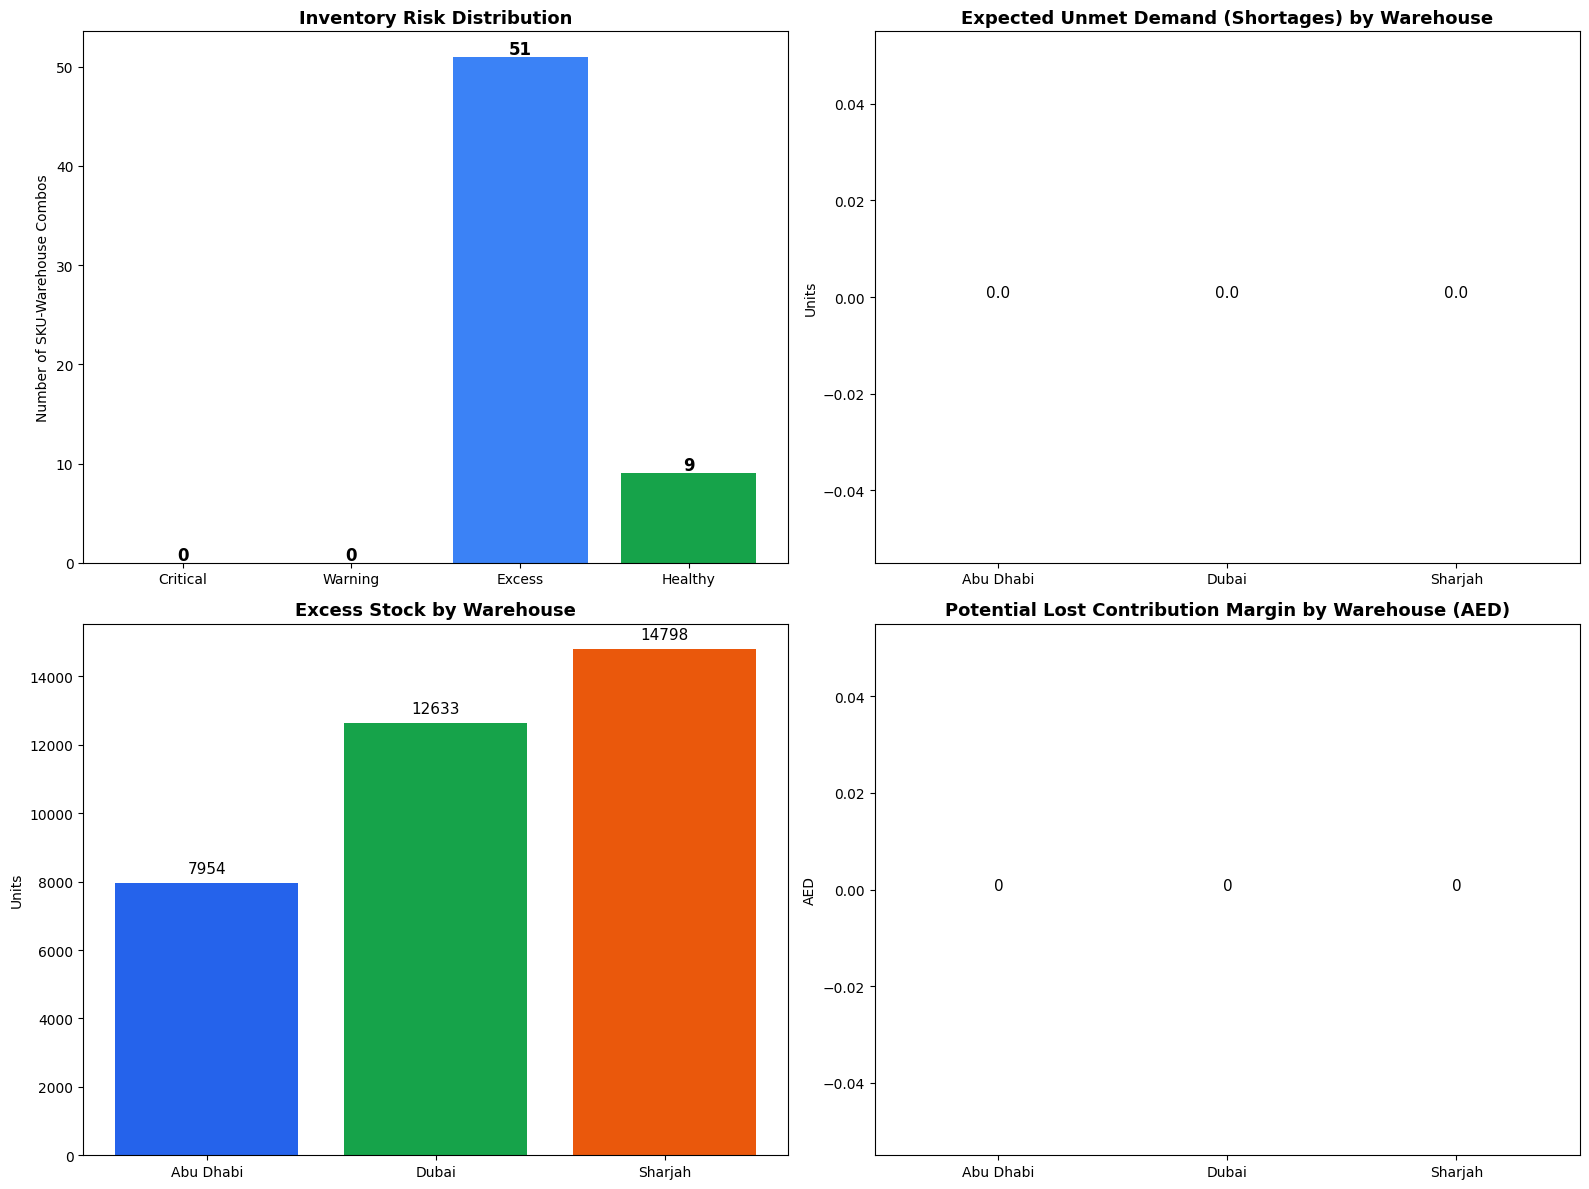

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\inventory_risk_charts.png


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Risk distribution pie/bar
ax = axes[0, 0]
risk_order = ["Critical", "Warning", "Excess", "Healthy"]
risk_colors = {"Critical": "#dc2626", "Warning": "#f59e0b", "Excess": "#3b82f6", "Healthy": "#16a34a"}
counts = [risk_counts.get(r, 0) for r in risk_order]
colors = [risk_colors[r] for r in risk_order]
ax.bar(risk_order, counts, color=colors)
ax.set_title("Inventory Risk Distribution", fontweight="bold", fontsize=13)
ax.set_ylabel("Number of SKU-Warehouse Combos")
for i, v in enumerate(counts):
    ax.text(i, v + 0.3, str(v), ha="center", fontsize=12, fontweight="bold")

# 2. Shortages by warehouse
ax = axes[0, 1]
wh_short = inv_risk.groupby("Warehouse")["Expected_Unmet_Demand"].sum()
ax.bar(wh_short.index, wh_short.values, color=["#2563eb", "#16a34a", "#ea580c"])
ax.set_title("Expected Unmet Demand (Shortages) by Warehouse", fontweight="bold", fontsize=13)
ax.set_ylabel("Units")
for i, (wh, v) in enumerate(wh_short.items()):
    ax.text(i, v + max(wh_short)*0.02, f"{v:.1f}", ha="center", fontsize=11)

# 3. Excess stock by warehouse
ax = axes[1, 0]
wh_excess = inv_risk.groupby("Warehouse")["Excess_Stock"].sum()
ax.bar(wh_excess.index, wh_excess.values, color=["#2563eb", "#16a34a", "#ea580c"])
ax.set_title("Excess Stock by Warehouse", fontweight="bold", fontsize=13)
ax.set_ylabel("Units")
for i, (wh, v) in enumerate(wh_excess.items()):
    ax.text(i, v + max(wh_excess)*0.02, f"{v:.0f}", ha="center", fontsize=11)

# 4. Lost margin by warehouse
ax = axes[1, 1]
wh_margin = inv_risk.groupby("Warehouse")["Lost_Contribution_Margin_AED"].sum()
ax.bar(wh_margin.index, wh_margin.values, color=["#2563eb", "#16a34a", "#ea580c"])
ax.set_title("Potential Lost Contribution Margin by Warehouse (AED)", fontweight="bold", fontsize=13)
ax.set_ylabel("AED")
for i, (wh, v) in enumerate(wh_margin.items()):
    ax.text(i, v + max(wh_margin)*0.02, f"{v:,.0f}", ha="center", fontsize=11)

plt.tight_layout()
plt.savefig(DATA_DIR / "inventory_risk_charts.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {DATA_DIR / 'inventory_risk_charts.png'}")

---
## 9. Validation Checks

In [19]:
print("=" * 65)
print("  VALIDATION CHECKS — Step 3: Inventory Risk Detection")
print("=" * 65)

# 1. Exactly 60 SKU-warehouse combinations
assert len(inventory_risks) == 60, f"Expected 60 combos, got {len(inventory_risks)}"
print(f"  ✅ SKU×Warehouse combos       : {len(inventory_risks)} (expected 60)")

# 2. Exactly 1,800 daily inventory projections
assert len(daily_proj_save) == 1800, f"Expected 1800, got {len(daily_proj_save)}"
print(f"  ✅ Daily projections          : {len(daily_proj_save)} (expected 1800)")

# 3. No negative physical inventory
assert (daily_proj_save["Ending_Stock"] < 0).sum() == 0, "Negative ending stock found!"
print(f"  ✅ No negative inventory      : max neg = {(daily_proj_save['Ending_Stock'] < 0).sum()}")

# 4. No missing or duplicated SKU-Warehouse-Date records
dups = daily_proj_save.duplicated(subset=["Date", "SKU", "Warehouse"]).sum()
missing = daily_proj_save[["Date", "SKU", "Warehouse", "Ending_Stock"]].isna().any().any()
assert dups == 0, f"Found {dups} duplicates"
assert not missing, "Missing records found"
print(f"  ✅ No duplicates              : {dups}")
print(f"  ✅ No missing records        : {not missing}")

# 5. Incoming shipments applied on correct dates
# Check that inbound quantities appear in daily projection on their arrival dates
inbound_check_ok = True
for _, row in inbound.iterrows():
    sku, wh, dt, qty = row["SKU"], row["Warehouse"], row["Expected_Arrival"], row["Quantity"]
    proj_row = daily_proj_save[
        (daily_proj_save["SKU"] == sku) &
        (daily_proj_save["Warehouse"] == wh) &
        (daily_proj_save["Date"] == dt.strftime("%Y-%m-%d"))
    ]
    if len(proj_row) == 0 or proj_row["Incoming_Qty"].values[0] != qty:
        inbound_check_ok = False
        break
assert inbound_check_ok, "Inbound shipments not applied correctly!"
print(f"  ✅ Inbound shipments correct  : all {len(inbound)} orders verified on arrival dates")

# 6. Daily inventory balances reconcile
# For each SKU-Warehouse, check that Starting_Stock[t+1] == Ending_Stock[t]
reconcile_ok = True
for (sku, wh), grp in daily_proj_save.groupby(["SKU", "Warehouse"]):
    grp = grp.sort_values("Date").reset_index(drop=True)
    for i in range(len(grp) - 1):
        ending = grp.loc[i, "Ending_Stock"]
        starting_next = grp.loc[i + 1, "Starting_Stock"]
        if abs(ending - starting_next) > 0.01:
            reconcile_ok = False
            break
    if not reconcile_ok:
        break
assert reconcile_ok, "Daily inventory does not reconcile!"
print(f"  ✅ Daily balances reconcile   : Starting[t+1] == Ending[t]")

# 7. All forecasts from improved XGBoost model
assert (inventory_risks["Selected_Model"] == "Tuned XGBoost").all(), "Not all from XGBoost!"
print(f"  ✅ All forecasts from XGBoost : {(inventory_risks['Selected_Model'] == 'Tuned XGBoost').sum()}/60")

# 8. No negative ending stock in inventory_risks
assert (inventory_risks["Ending_Stock"] < 0).sum() == 0
print(f"  ✅ No negative ending stock   : verified")

# 9. Unmet demand >= 0
assert (inventory_risks["Expected_Unmet_Demand"] >= 0).all()
print(f"  ✅ Unmet demand ≥ 0           : verified")

# 10. Safety shortfall >= 0
assert (inventory_risks["Safety_Stock_Shortfall"] >= 0).all()
print(f"  ✅ Safety shortfall ≥ 0       : verified")

# 11. 30 unique dates
assert daily_proj_save["Date"].nunique() == 30
print(f"  ✅ Unique forecast dates      : {daily_proj_save['Date'].nunique()} (expected 30)")

print("=" * 65)
print("  ALL VALIDATION CHECKS PASSED ✅")
print("=" * 65)

  VALIDATION CHECKS — Step 3: Inventory Risk Detection
  ✅ SKU×Warehouse combos       : 60 (expected 60)
  ✅ Daily projections          : 1800 (expected 1800)
  ✅ No negative inventory      : max neg = 0
  ✅ No duplicates              : 0
  ✅ No missing records        : True
  ✅ Inbound shipments correct  : all 42 orders verified on arrival dates
  ✅ Daily balances reconcile   : Starting[t+1] == Ending[t]
  ✅ All forecasts from XGBoost : 60/60
  ✅ No negative ending stock   : verified
  ✅ Unmet demand ≥ 0           : verified
  ✅ Safety shortfall ≥ 0       : verified
  ✅ Unique forecast dates      : 30 (expected 30)
  ALL VALIDATION CHECKS PASSED ✅


---

## 10. Summary — Step 3 Complete

```
✅ Step 3: Inventory Risk Detection — complete.

Files Created:
  • inventory_risks.csv            — 60 rows (one per SKU-warehouse)
  • daily_inventory_projection.csv — 1,800 rows (30 days × 60 combos)
  • inventory_risk_summary.csv     — summary metrics
  • inventory_risk_charts.png      — 4-panel visualization

Risk Classification:
  • Critical (unmet demand expected)
  • Warning (below safety stock, no unmet demand)
  • Excess (stock > 2× safety AND > 2× forecast)
  • Healthy

Daily Simulation:
  • Shipment timing modelled per Expected_Arrival
  • Physical stock never goes negative
  • First stockout date tracked
  • Safety-stock violations tracked

Stock Ageing:
  • 61-90 day and 90+ day buckets analyzed
  • Holding costs estimated
  • High/critical ageing flags set

Financial Impact (simulated estimates):
  • Lost contribution margin from unmet demand
  • Aged stock holding costs
  • Excess stock holding costs
  • Total financial exposure by warehouse

All validation checks passed.
All original files preserved.
Step 4 not implemented yet.
```